In [1]:
import os
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

# Define the base directories
data_dir = Path(r"/kaggle/input/power-system/segmentation_data/fllanza_data")
labels_dir = Path(r"/kaggle/input/power-system/segmentation_labels/segmentation_labels")

# Function to load labels into a separate dataframe
def load_labels(label_file):
    labels_df = pd.read_csv(labels_dir / label_file)
    labels_df_cleaned = labels_df.dropna().copy()  # Ensure it's a copy
    labels_df_cleaned["sample_id"] = labels_df_cleaned["sample_id"].astype(int)
    return labels_df_cleaned  # Return the cleaned labels DataFrame

# Function to load measurement data into a separate dataframe
def load_measurements(segment_folder):
    combined_data = []

    # Loop through all sample folders
    for sample_folder in data_dir.iterdir():
        if sample_folder.is_dir():
            sample_id = sample_folder.name  # Extract sample ID from folder name
            measurement_file = sample_folder / segment_folder / "measurements.csv"
            
            if measurement_file.exists():
                df = pd.read_csv(measurement_file)
                df["Time"] = pd.to_numeric(df["Time"])  # Ensure 'Time' column is numeric
                df["sample_id"] = int(sample_id)  # Store sample_id
                combined_data.append(df)
            else:
                print(f"Measurements file not found for Sample ID {sample_id} in {segment_folder}.")

    # Concatenate all data
    if combined_data:
        measurements_df = pd.concat(combined_data, ignore_index=True)
        measurements_df["sample_id"] = measurements_df["sample_id"].astype(int)
        return measurements_df
    else:
        return pd.DataFrame()

# Load J03 and J04 labels
labels_J03 = load_labels("J03_labels.csv")
labels_J04 = load_labels("J04_labels.csv")

# Load J03 and J04 measurement data
measurements_J03 = load_measurements("J03")
measurements_J04 = load_measurements("J04")

# Display both separate dataframes
print("Labels DataFrame:")
print(labels_J03.head())

print("\nMeasurements DataFrame:")
print(measurements_J03.head())

# Sort by 'sample_id' first, then by 'Time' within each sample_id
measurements_J03 = measurements_J03.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)
# Sort by 'sample_id' first, then by 'Time' within each sample_id
measurements_J04 = measurements_J04.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)

Measurements file not found for Sample ID 3531 in J03.
Measurements file not found for Sample ID 15244 in J03.
Measurements file not found for Sample ID 8676 in J03.
Measurements file not found for Sample ID 26404 in J03.
Measurements file not found for Sample ID 7310 in J03.
Measurements file not found for Sample ID 8715 in J03.
Measurements file not found for Sample ID 6025 in J03.
Measurements file not found for Sample ID 30786 in J03.
Measurements file not found for Sample ID 4371 in J03.
Measurements file not found for Sample ID 27134 in J03.
Measurements file not found for Sample ID 22706 in J03.
Measurements file not found for Sample ID 17184 in J03.
Measurements file not found for Sample ID 3562 in J03.
Measurements file not found for Sample ID 11496 in J03.
Measurements file not found for Sample ID 20826 in J03.
Measurements file not found for Sample ID 22999 in J03.
Measurements file not found for Sample ID 8912 in J03.
Measurements file not found for Sample ID 8685 in J03.
M

In [2]:
# from sklearn.preprocessing import RobustScaler
# # Define phase columns
# voltage_columns = ["U1", "U2", "U3"]
# current_columns = ["I1", "I2", "I3"]

# # Create a RobustScaler instance
# scaler = RobustScaler()

# # Normalize voltage and current columns before RMS calculation
# measurements_J03[voltage_columns] = scaler.fit_transform(measurements_J03[voltage_columns])
# # measurements_J03[current_columns] = scaler.fit_transform(measurements_J03[current_columns])

# # Normalize voltage and current columns before RMS calculation
# measurements_J04[voltage_columns] = scaler.fit_transform(measurements_J04[voltage_columns])
# # measurements_J04[current_columns] = scaler.fit_transform(measurements_J04[current_columns])

In [3]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import RobustScaler

# Define phase columns
voltage_columns = ["U1", "U2", "U3"]

# Function to apply RobustScaler for a specific sample_id
def apply_robust_scaling(df, sample_id, columns):
    sample_data = df[df['sample_id'] == sample_id].copy()  # Filter data for the sample
    
    scaler = RobustScaler()  # Initialize RobustScaler
    df.loc[df['sample_id'] == sample_id, columns] = scaler.fit_transform(sample_data[columns])  # Apply scaling

# Apply RobustScaler to measurements_J03
sample_ids_J03 = measurements_J03['sample_id'].unique()

for sample_id in sample_ids_J03:
    apply_robust_scaling(measurements_J03, sample_id, voltage_columns)

# Apply RobustScaler to measurements_J04
sample_ids_J04 = measurements_J04['sample_id'].unique()

for sample_id in sample_ids_J04:
    apply_robust_scaling(measurements_J04, sample_id, voltage_columns)


In [4]:
current_columns = ["I1", "I2", "I3"]

def normalize_using_first_two_cycles_amplitude(df, columns):
    """
    Normalize each sample using the amplitude (max - min) of the first two cycles (0.04s).
    """
    normalized_df = df.copy()

    for sample_id in df["sample_id"].unique():
        sample_df = df[df["sample_id"] == sample_id].copy()

        # Define the first two cycles as the first 0.04 seconds
        start_time = sample_df["Time"].min()
        time_threshold = start_time + 0.04
        first_two_cycles = sample_df[sample_df["Time"] <= time_threshold]

        if not first_two_cycles.empty:
            # Compute amplitude (max - min) for each column
            amplitude = first_two_cycles[columns].max() - first_two_cycles[columns].min()

            # Avoid division by zero (if amplitude is 0, set to 1)
            amplitude.replace(0, 1, inplace=True)

            # Normalize the entire sample
            normalized_df.loc[df["sample_id"] == sample_id, columns] = sample_df[columns] / amplitude

    return normalized_df

# Apply normalization to current signals
measurements_J03 = normalize_using_first_two_cycles_amplitude(measurements_J03, current_columns)
measurements_J04 = normalize_using_first_two_cycles_amplitude(measurements_J04, current_columns)

In [5]:
import numpy as np
import pandas as pd

# Function to calculate RMS for each segment (40 samples)
def calculate_rms_by_segments(df, voltage_columns, current_columns, segment_size=40):
    rms_values = []

    # Iterate through unique sample IDs
    for sample_id in df["sample_id"].unique():
        sample_data = df[df["sample_id"] == sample_id].reset_index(drop=True)

        num_samples = len(sample_data)

        # Segment the data in chunks of 'segment_size'
        for start_idx in range(1, num_samples, segment_size):
            end_idx = min(start_idx + segment_size, num_samples)
            segment_df = sample_data.iloc[start_idx:end_idx]

            # Compute RMS for this segment
            rms_segment = {"sample_id": sample_id, "Segment": start_idx // segment_size + 1}

            for phase in voltage_columns:
                rms_segment[f"RMS_{phase}"] = np.sqrt(np.mean(segment_df[phase] ** 2))

            for phase in current_columns:
                rms_segment[f"RMS_{phase}"] = np.sqrt(np.mean(segment_df[phase] ** 2))

            # Store the end time of the segment
            rms_segment["Time"] = segment_df.iloc[-1]["Time"]

            rms_values.append(rms_segment)

    return pd.DataFrame(rms_values)



# Calculate RMS on the filtered signals
rms_df = calculate_rms_by_segments(measurements_J03, voltage_columns, current_columns)
rms_df2 = calculate_rms_by_segments(measurements_J04, voltage_columns, current_columns)

# Sort and reset index
rms_df = rms_df.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)
rms_df2 = rms_df2.sort_values(by=["sample_id", "Time"]).reset_index(drop=True)

In [6]:
def compute_derivative(rms_df, voltage_columns, current_columns):
    new_df = rms_df.copy()  # Create a copy to avoid chained assignment issues
    
    # Process each unique sample_id separately
    for sample_id in new_df["sample_id"].unique():
        # Get data for this sample_id
        sample_mask = new_df["sample_id"] == sample_id
        sample_data = new_df[sample_mask]
        
        # Get indices for this sample in the original dataframe
        sample_indices = sample_data.index
        
        for phase in voltage_columns + current_columns:
            rms_col = f"RMS_{phase}"
            dy_dx_col = f"d_{phase}/dt"   # First derivative
            d2y_dx2_col = f"d2_{phase}/dt2"  # Second derivative
            
            # Compute derivatives only for this sample
            dy_dx_values = np.gradient(sample_data[rms_col], sample_data["Time"])
            d2y_dx2_values = np.gradient(dy_dx_values, sample_data["Time"])
            
            # Assign computed values back to the original dataframe at the correct indices
            new_df.loc[sample_indices, dy_dx_col] = dy_dx_values
            new_df.loc[sample_indices, d2y_dx2_col] = d2y_dx2_values
    
    return new_df  # Return the updated DataFrame

# Apply derivative computation to both datasets
rms_df = compute_derivative(rms_df, voltage_columns, current_columns)
rms_df2 = compute_derivative(rms_df2, voltage_columns, current_columns)

In [7]:
import numpy as np
import pandas as pd

def normalize_derivatives(df, voltage_columns, current_columns, method='z-score'):
    """
    Normalize the derivatives using different methods
    
    Parameters:
    -----------
    df : pandas.DataFrame
        Input dataframe with derivatives
    voltage_columns : list
        List of voltage column names
    current_columns : list
        List of current column names
    method : str, optional (default='z-score')
        Normalization method to use. Options:
        - 'z-score': Standard scaling (zero mean, unit variance)
        - 'min-max': Scale to [0, 1] range
        - 'robust': Scaling using median and interquartile range
    
    Returns:
    --------
    pandas.DataFrame
        Dataframe with normalized derivatives
    """
    new_df = df.copy()
    
    # Columns to normalize
    derivative_columns = []
    for phase in voltage_columns + current_columns:
        derivative_columns.extend([f"d_{phase}/dt", f"d2_{phase}/dt2"])
    
    if method == 'z-score':
        # Z-score normalization (standard scaling)
        for col in derivative_columns:
            new_df[f'norm_{col}'] = (new_df[col] - new_df[col].mean()) / new_df[col].std()
    
    elif method == 'min-max':
        # Min-Max scaling to [0, 1] range
        for col in derivative_columns:
            min_val = new_df[col].min()
            max_val = new_df[col].max()
            new_df[f'norm_{col}'] = (new_df[col] - min_val) / (max_val - min_val)
    
    elif method == 'robust':
        # Robust scaling using median and interquartile range
        for col in derivative_columns:
            median = new_df[col].median()
            iqr = new_df[col].quantile(0.75) - new_df[col].quantile(0.25)
            new_df[f'norm_{col}'] = (new_df[col] - median) / iqr
    
    else:
        raise ValueError("Invalid normalization method. Choose 'z-score', 'min-max', or 'robust'.")
    
    return new_df

# Example usage
# Assuming rms_df and rms_df2 are your dataframes
rms_df = normalize_derivatives(rms_df, voltage_columns, current_columns, method='min-max')
rms_df2= normalize_derivatives(rms_df2, voltage_columns, current_columns, method='min-max')

In [8]:
rms_df.head()

,sample_id,Segment,RMS_U1,RMS_U2,RMS_U3,RMS_I1,RMS_I2,RMS_I3,Time,d_U1/dt,...,norm_d_U2/dt,norm_d2_U2/dt2,norm_d_U3/dt,norm_d2_U3/dt2,norm_d_I1/dt,norm_d2_I1/dt2,norm_d_I2/dt,norm_d2_I2/dt2,norm_d_I3/dt,norm_d2_I3/dt2
0,14,1,0.503216,0.513468,0.516138,0.348703,0.332570,0.346571,0.01,0.223844,...,0.323746,0.304408,0.942488,0.953785,0.411114,0.565879,0.356743,0.608518,0.513882,0.585541
1,14,2,0.505454,0.513772,0.519212,0.339100,0.341626,0.349580,0.02,-0.025202,...,0.323652,0.304437,0.942012,0.954035,0.411124,0.565872,0.356735,0.608522,0.513878,0.585545
2,14,3,0.502712,0.513476,0.515931,0.349631,0.332011,0.345714,0.03,0.024364,...,0.323610,0.304515,0.941995,0.954316,0.411124,0.565866,0.356734,0.608528,0.513879,0.585550
3,14,4,0.505941,0.513515,0.518776,0.340232,0.338336,0.350391,0.04,0.011296,...,0.323657,0.304549,0.942036,0.954339,0.411124,0.565865,0.356736,0.608529,0.513881,0.585548
4,14,5,0.502938,0.513515,0.516039,0.351704,0.333375,0.349753,0.05,-0.012757,...,0.323677,0.304528,0.942062,0.954286,0.411123,0.565864,0.356736,0.608527,0.513880,0.585544


In [9]:
import numpy as np
import pandas as pd

# Function to create labels dynamically according to rms_df
def create_dynamic_labels(rms_df, labels_df):
    # Initialize empty lists to store start_t and end_t for each row
    start_times = []
    end_times = []

    # Iterate through each sample_id in the rms_df
    for sample_id in rms_df["sample_id"].unique():
        # Get all labels for the current sample_id
        sample_labels = labels_df[labels_df["sample_id"] == sample_id]

        # Get the time intervals for the sample_id
        sample_times = sample_labels[['start_t', 'end_t']].values

        # Sort the time intervals in case they are not in order
        sample_times = sorted(sample_times, key=lambda x: x[0])

        # Get the rows in rms_df corresponding to this sample_id
        sample_rms = rms_df[rms_df["sample_id"] == sample_id].reset_index(drop=True)

        # Iterate through the rows of sample_rms and assign the correct start_t and end_t
        label_idx = 0
        for idx, row in sample_rms.iterrows():
            # Assign the current start_t and end_t to this row
            start_times.append(sample_times[label_idx][0])
            end_times.append(sample_times[label_idx][1])

            # Check if we need to switch to the next label (after the end_t time is passed)
            if row["Time"] > sample_times[label_idx][1]:
                # Switch to the next label if available
                if label_idx + 1 < len(sample_times):
                    label_idx += 1

    # Add the start and end times as new columns to the rms_df
    rms_df["start_t"] = start_times
    rms_df["end_t"] = end_times

    return rms_df


# Example Usage:
# Create the dynamic labels for rms_df based on the labels in labels_J03
rms_df_with_labels = create_dynamic_labels(rms_df, labels_J03)
rms_df_with_labels2 = create_dynamic_labels(rms_df2, labels_J04)

# Display the first few rows with the new labels
print(rms_df_with_labels.head())

   sample_id  Segment    RMS_U1    RMS_U2    RMS_U3    RMS_I1    RMS_I2  \
0         14        1  0.503216  0.513468  0.516138  0.348703  0.332570   
1         14        2  0.505454  0.513772  0.519212  0.339100  0.341626   
2         14        3  0.502712  0.513476  0.515931  0.349631  0.332011   
3         14        4  0.505941  0.513515  0.518776  0.340232  0.338336   
4         14        5  0.502938  0.513515  0.516039  0.351704  0.333375   

     RMS_I3  Time   d_U1/dt  ...  norm_d_U3/dt  norm_d2_U3/dt2  norm_d_I1/dt  \
0  0.346571  0.01  0.223844  ...      0.942488        0.953785      0.411114   
1  0.349580  0.02 -0.025202  ...      0.942012        0.954035      0.411124   
2  0.345714  0.03  0.024364  ...      0.941995        0.954316      0.411124   
3  0.350391  0.04  0.011296  ...      0.942036        0.954339      0.411124   
4  0.349753  0.05 -0.012757  ...      0.942062        0.954286      0.411123   

   norm_d2_I1/dt2  norm_d_I2/dt  norm_d2_I2/dt2  norm_d_I3/dt  norm_

In [10]:
rms_df_with_labels[rms_df_with_labels["sample_id"] == 924]

,sample_id,Segment,RMS_U1,RMS_U2,RMS_U3,RMS_I1,RMS_I2,RMS_I3,Time,d_U1/dt,...,norm_d_U3/dt,norm_d2_U3/dt2,norm_d_I1/dt,norm_d2_I1/dt2,norm_d_I2/dt,norm_d2_I2/dt2,norm_d_I3/dt,norm_d2_I3/dt2,start_t,end_t
3000,924,1,0.483976,0.460819,0.589543,0.338295,0.334331,0.350414,0.01000,-0.570309,...,0.941773,0.954593,0.411130,0.565858,0.356740,0.608523,0.513870,0.585563,0.493674,0.822858
3001,924,2,0.478273,0.459974,0.587844,0.345211,0.340557,0.343125,0.02000,-0.008724,...,0.942040,0.954488,0.411125,0.565861,0.356737,0.608524,0.513880,0.585555,0.493674,0.822858
3002,924,3,0.483801,0.460412,0.589701,0.341105,0.337369,0.352460,0.03000,-0.001526,...,0.942113,0.954307,0.411124,0.565864,0.356734,0.608527,0.513879,0.585546,0.493674,0.822858
3003,924,4,0.478242,0.459775,0.588979,0.346362,0.336482,0.343960,0.04000,-0.005056,...,0.942047,0.954235,0.411122,0.565865,0.356735,0.608530,0.513878,0.585547,0.493674,0.822858
3004,924,5,0.483700,0.460215,0.589957,0.338300,0.336966,0.351829,0.05000,0.010763,...,0.941987,0.954288,0.411124,0.565867,0.356738,0.608528,0.513878,0.585548,0.493674,0.822858
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3146,924,147,0.482801,0.459241,0.591374,0.344962,0.333186,0.354665,1.47000,0.018989,...,0.941947,0.954297,0.411124,0.565867,0.356735,0.608530,0.513878,0.585547,0.993885,1.365917
3147,924,148,0.478040,0.460207,0.591789,0.348988,0.346145,0.341913,1.48000,-0.004414,...,0.941992,0.954335,0.411125,0.565865,0.356736,0.608528,0.513879,0.585547,0.993885,1.365917
3148,924,149,0.482712,0.459396,0.590898,0.347399,0.335853,0.355330,1.49000,0.013035,...,0.942006,0.477219,0.411123,0.567160,0.356735,0.608120,0.513877,0.584175,0.993885,1.365917
3149,924,150,0.478301,0.460488,0.591496,0.347338,0.346642,0.339594,1.50000,58.303927,...,0.065730,0.000008,0.412880,0.568455,0.356067,0.607705,0.512177,0.582831,0.993885,1.365917


In [11]:
# Count the number of rows per sample_id
sample_sizes = rms_df_with_labels.groupby('sample_id').size()

# Filter out sample_ids with more than 100 rows
samples_to_keep = sample_sizes[sample_sizes <= 100].index

# Filter the original DataFrame to keep only these samples
rms_df_filtered = rms_df_with_labels[rms_df_with_labels['sample_id'].isin(samples_to_keep)]



# Count the number of rows per sample_id
sample_sizes = rms_df_with_labels2.groupby('sample_id').size()

# Filter out sample_ids with more than 100 rows
samples_to_keep = sample_sizes[sample_sizes <= 100].index

# Filter the original DataFrame to keep only these samples
rms_df_filtered2 = rms_df_with_labels2[rms_df_with_labels2['sample_id'].isin(samples_to_keep)]

In [12]:
import numpy as np
from sklearn.model_selection import train_test_split


# Step 1: Create Sequences and Track Indices
def create_sequences_with_indices(X, y, time, time_steps=50):
    X_seq, y_seq, time_seq, indices = [], [], [], []
    for i in range(0,len(X) - time_steps,time_steps):
        X_seq.append(X[i:i + time_steps])
        y_seq.append(y[i + 1])
        time_seq.append(time[i + time_steps])
        indices.append(i)  # Store the original index
    return np.array(X_seq), np.array(y_seq), np.array(time_seq), np.array(indices)

In [13]:
# Define features for each phase
phase1_voltage_features = ['RMS_U1', 'd_U1/dt']
phase2_voltage_features = ['RMS_U2', 'd_U2/dt']
phase3_voltage_features = ['RMS_U3', 'd_U3/dt']

phase1_current_features = ['RMS_I1', 'd_I1/dt']
phase2_current_features = ['RMS_I2', 'd_I2/dt']
phase3_current_features = ['RMS_I3', 'd_I3/dt']

labels = ['start_t', 'end_t']

# Extract each phase's features separately
# Phase 1
X1_voltage_phase1 = rms_df_filtered[phase1_voltage_features].values
X1_current_phase1 = rms_df_filtered[phase1_current_features].values
X2_voltage_phase1 = rms_df_filtered2[phase1_voltage_features].values
X2_current_phase1 = rms_df_filtered2[phase1_current_features].values

# Phase 2
X1_voltage_phase2 = rms_df_filtered[phase2_voltage_features].values
X1_current_phase2 = rms_df_filtered[phase2_current_features].values
X2_voltage_phase2 = rms_df_filtered2[phase2_voltage_features].values
X2_current_phase2 = rms_df_filtered2[phase2_current_features].values

# Phase 3
X1_voltage_phase3 = rms_df_filtered[phase3_voltage_features].values
X1_current_phase3 = rms_df_filtered[phase3_current_features].values
X2_voltage_phase3 = rms_df_filtered2[phase3_voltage_features].values
X2_current_phase3 = rms_df_filtered2[phase3_current_features].values

# Labels remain the same
y1 = rms_df_filtered[labels].values
y2 = rms_df_filtered2[labels].values
time_values1 = rms_df_filtered['Time'].values
time_values2 = rms_df_filtered2['Time'].values

# For demonstration, I'll continue with Phase 1 data splitting
# You can repeat this process for phases 2 and 3
test_size = 2500

# Split Phase 1 Voltage Data
X_train1_v_phase1, X_test1_v_phase1 = X1_voltage_phase1[:-test_size], X1_voltage_phase1[-test_size:]
X_train2_v_phase1, X_test2_v_phase1 = X2_voltage_phase1[:-test_size], X2_voltage_phase1[-test_size:]

# Split Phase 1 Current Data
X_train1_c_phase1, X_test1_c_phase1 = X1_current_phase1[:-test_size], X1_current_phase1[-test_size:]
X_train2_c_phase1, X_test2_c_phase1 = X2_current_phase1[:-test_size], X2_current_phase1[-test_size:]

# Labels and Time Values
y_train1, y_test1 = y1[:-test_size], y1[-test_size:]
y_train2, y_test2 = y2[:-test_size], y2[-test_size:]
time_train1, time_test1 = time_values1[:-test_size], time_values1[-test_size:]
time_train2, time_test2 = time_values2[:-test_size], time_values2[-test_size:]

# Concatenate Phase 1 Training Data
X_train_v_phase1 = np.concatenate([X_train1_v_phase1, X_train2_v_phase1], axis=0)
X_train_c_phase1 = np.concatenate([X_train1_c_phase1, X_train2_c_phase1], axis=0)
y_train = np.concatenate([y_train1, y_train2], axis=0)
time_train = np.concatenate([time_train1, time_train2], axis=0)

# Concatenate Phase 1 Testing Data
X_test_v_phase1 = np.concatenate([X_test1_v_phase1, X_test2_v_phase1], axis=0)
X_test_c_phase1 = np.concatenate([X_test1_c_phase1, X_test2_c_phase1], axis=0)
y_test = np.concatenate([y_test1, y_test2], axis=0)
time_test = np.concatenate([time_test1, time_test2], axis=0)

# Split into Train and Validation for Phase 1
X_train_v_phase1_final, X_val_v_phase1, y_train_final, y_val, time_train_final, time_val = train_test_split(
    X_train_v_phase1, y_train, time_train, test_size=2500, random_state=42, shuffle=False
)
X_train_c_phase1_final, X_val_c_phase1, _, _, _, _ = train_test_split(
    X_train_c_phase1, y_train, time_train, test_size=2500, random_state=42, shuffle=False
)

# Apply Windowing to Phase 1 Voltage Data
X_train_v_phase1_seq, y_train_seq, time_train_seq, _ = create_sequences_with_indices(
    X_train_v_phase1_final, y_train_final, time_train_final, time_steps=100
)
X_val_v_phase1_seq, y_val_seq, time_val_seq, _ = create_sequences_with_indices(
    X_val_v_phase1, y_val, time_val, time_steps=100
)

# Apply Windowing to Phase 1 Current Data
X_train_c_phase1_seq, _, _, _ = create_sequences_with_indices(
    X_train_c_phase1_final, y_train_final, time_train_final, time_steps=100
)
X_val_c_phase1_seq, _, _, _ = create_sequences_with_indices(
    X_val_c_phase1, y_val, time_val, time_steps=100
)

In [14]:
# Split Phase 1 Voltage Data
X_train1_v_phase2, X_test1_v_phase2 = X1_voltage_phase2[:-test_size], X1_voltage_phase2[-test_size:]
X_train2_v_phase2, X_test2_v_phase2 = X2_voltage_phase2[:-test_size], X2_voltage_phase2[-test_size:]

# Split Phase 1 Current Data
X_train1_c_phase2, X_test1_c_phase2 = X1_current_phase2[:-test_size], X1_current_phase2[-test_size:]
X_train2_c_phase2, X_test2_c_phase2 = X2_current_phase2[:-test_size], X2_current_phase2[-test_size:]

# Labels and Time Values
y_train1, y_test1 = y1[:-test_size], y1[-test_size:]
y_train2, y_test2 = y2[:-test_size], y2[-test_size:]
time_train1, time_test1 = time_values1[:-test_size], time_values1[-test_size:]
time_train2, time_test2 = time_values2[:-test_size], time_values2[-test_size:]

# Concatenate Phase 1 Training Data
X_train_v_phase2 = np.concatenate([X_train1_v_phase2, X_train2_v_phase2], axis=0)
X_train_c_phase2 = np.concatenate([X_train1_c_phase2, X_train2_c_phase2], axis=0)
y_train = np.concatenate([y_train1, y_train2], axis=0)
time_train = np.concatenate([time_train1, time_train2], axis=0)

# Concatenate Phase 1 Testing Data
X_test_v_phase2 = np.concatenate([X_test1_v_phase2, X_test2_v_phase2], axis=0)
X_test_c_phase2 = np.concatenate([X_test1_c_phase2, X_test2_c_phase2], axis=0)
y_test = np.concatenate([y_test1, y_test2], axis=0)
time_test = np.concatenate([time_test1, time_test2], axis=0)

# Split into Train and Validation for Phase 1
X_train_v_phase2_final, X_val_v_phase2, y_train_final, y_val, time_train_final, time_val = train_test_split(
    X_train_v_phase2, y_train, time_train, test_size=2500, random_state=42, shuffle=False
)
X_train_c_phase2_final, X_val_c_phase2, _, _, _, _ = train_test_split(
    X_train_c_phase2, y_train, time_train, test_size=2500, random_state=42, shuffle=False
)

# Apply Windowing to Phase 1 Voltage Data
X_train_v_phase2_seq, y_train_seq, time_train_seq, _ = create_sequences_with_indices(
    X_train_v_phase2_final, y_train_final, time_train_final, time_steps=100
)
X_val_v_phase2_seq, y_val_seq, time_val_seq, _ = create_sequences_with_indices(
    X_val_v_phase2, y_val, time_val, time_steps=100
)

# Apply Windowing to Phase 1 Current Data
X_train_c_phase2_seq, _, _, _ = create_sequences_with_indices(
    X_train_c_phase2_final, y_train_final, time_train_final, time_steps=100
)
X_val_c_phase2_seq, _, _, _ = create_sequences_with_indices(
    X_val_c_phase2, y_val, time_val, time_steps=100
)

In [15]:
# Split Phase 1 Voltage Data
X_train1_v_phase3, X_test1_v_phase3 = X1_voltage_phase3[:-test_size], X1_voltage_phase3[-test_size:]
X_train2_v_phase3, X_test2_v_phase3 = X2_voltage_phase3[:-test_size], X2_voltage_phase3[-test_size:]

# Split Phase 1 Current Data
X_train1_c_phase3, X_test1_c_phase3 = X1_current_phase3[:-test_size], X1_current_phase3[-test_size:]
X_train2_c_phase3, X_test2_c_phase3 = X2_current_phase3[:-test_size], X2_current_phase3[-test_size:]

# Labels and Time Values
y_train1, y_test1 = y1[:-test_size], y1[-test_size:]
y_train2, y_test2 = y2[:-test_size], y2[-test_size:]
time_train1, time_test1 = time_values1[:-test_size], time_values1[-test_size:]
time_train2, time_test2 = time_values2[:-test_size], time_values2[-test_size:]

# Concatenate Phase 1 Training Data
X_train_v_phase3 = np.concatenate([X_train1_v_phase3, X_train2_v_phase3], axis=0)
X_train_c_phase3 = np.concatenate([X_train1_c_phase3, X_train2_c_phase3], axis=0)
y_train = np.concatenate([y_train1, y_train2], axis=0)
time_train = np.concatenate([time_train1, time_train2], axis=0)

# Concatenate Phase 1 Testing Data
X_test_v_phase3 = np.concatenate([X_test1_v_phase3, X_test2_v_phase3], axis=0)
X_test_c_phase3 = np.concatenate([X_test1_c_phase3, X_test2_c_phase3], axis=0)
y_test = np.concatenate([y_test1, y_test2], axis=0)
time_test = np.concatenate([time_test1, time_test2], axis=0)

# Split into Train and Validation for Phase 1
X_train_v_phase3_final, X_val_v_phase3, y_train_final, y_val, time_train_final, time_val = train_test_split(
    X_train_v_phase3, y_train, time_train, test_size=2500, random_state=42, shuffle=False
)
X_train_c_phase3_final, X_val_c_phase3, _, _, _, _ = train_test_split(
    X_train_c_phase3, y_train, time_train, test_size=2500, random_state=42, shuffle=False
)

# Apply Windowing to Phase 1 Voltage Data
X_train_v_phase3_seq, y_train_seq, time_train_seq, _ = create_sequences_with_indices(
    X_train_v_phase3_final, y_train_final, time_train_final, time_steps=100
)
X_val_v_phase3_seq, y_val_seq, time_val_seq, _ = create_sequences_with_indices(
    X_val_v_phase3, y_val, time_val, time_steps=100
)

# Apply Windowing to Phase 1 Current Data
X_train_c_phase3_seq, _, _, _ = create_sequences_with_indices(
    X_train_c_phase3_final, y_train_final, time_train_final, time_steps=100
)
X_val_c_phase3_seq, _, _, _ = create_sequences_with_indices(
    X_val_c_phase3, y_val, time_val, time_steps=100
)

In [16]:
# Extract unique sample IDs for test data from each dataset separately
sample_ids_test1 = rms_df_filtered['sample_id'].iloc[-test_size:].unique()
sample_ids_test2 = rms_df_filtered2['sample_id'].iloc[-test_size:].unique()

# Concatenate the unique sample IDs while keeping duplicates from both datasets
final_sample_ids = np.concatenate([sample_ids_test1, sample_ids_test2])

# Optionally save to a file
np.savetxt("final_test_sample_ids_100.csv", final_sample_ids, delimiter=",", fmt="%s")

# Display first few sample IDs
print(len(final_sample_ids))  # Just to verify


50


In [17]:
import random
import numpy as np
import torch

# Set random seeds for reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)  # If using CUDA

# Define the sequence creation functions
def create_sequences_with_indices(X, y, time, time_steps=50):
    X_seq, y_seq, time_seq = [], [], []
    for i in range(0, len(X) , time_steps):
        X_seq.append(X[i:i + time_steps])
        y_seq.append(y[i + 1])
        time_seq.append(time[i:i + time_steps])
    return np.array(X_seq), np.array(y_seq), np.array(time_seq)

def create_windows_for_test(X, y, time, time_steps=50):
    X_seq, y_seq, time_seq = [], [], []
    for i in range(0, len(X), time_steps):
        X_seq.append(X[i:i + time_steps])
        y_seq.append(y[i +  1])
        time_seq.append(time[i:i + time_steps])
    return np.array(X_seq), np.array(y_seq), np.array(time_seq)

# Process each phase separately for validation data
# Phase 1
X_val_v_phase1_seq, y_val_phase1_seq, time_val_phase1_seq = create_sequences_with_indices(
    X_val_v_phase1, y_val, time_val, time_steps=100
)
X_val_c_phase1_seq, y_val_c_phase1_seq, time_val_c_phase1_seq = create_sequences_with_indices(
    X_val_c_phase1, y_val, time_val, time_steps=100
)

# Phase 2
X_val_v_phase2_seq, y_val_phase2_seq, time_val_phase2_seq = create_sequences_with_indices(
    X_val_v_phase2, y_val, time_val, time_steps=100
)
X_val_c_phase2_seq, y_val_c_phase2_seq, time_val_c_phase2_seq = create_sequences_with_indices(
    X_val_c_phase2, y_val, time_val, time_steps=100
)

# Phase 3
X_val_v_phase3_seq, y_val_phase3_seq, time_val_phase3_seq = create_sequences_with_indices(
    X_val_v_phase3, y_val, time_val, time_steps=100
)
X_val_c_phase3_seq, y_val_c_phase3_seq, time_val_c_phase3_seq = create_sequences_with_indices(
    X_val_c_phase3, y_val, time_val, time_steps=100
)

# Process each phase separately for test data
# Phase 1
X_test_v_phase1_seq, y_test_phase1_seq, time_test_phase1_seq = create_windows_for_test(
    X_test_v_phase1, y_test, time_test, time_steps=100
)
X_test_c_phase1_seq, y_test_c_phase1_seq, time_test_c_phase1_seq = create_windows_for_test(
    X_test_c_phase1, y_test, time_test, time_steps=100
)

# Phase 2
X_test_v_phase2_seq, y_test_phase2_seq, time_test_phase2_seq = create_windows_for_test(
    X_test_v_phase2, y_test, time_test, time_steps=100
)
X_test_c_phase2_seq, y_test_c_phase2_seq, time_test_c_phase2_seq = create_windows_for_test(
    X_test_c_phase2, y_test, time_test, time_steps=100
)

# Phase 3
X_test_v_phase3_seq, y_test_phase3_seq, time_test_phase3_seq = create_windows_for_test(
    X_test_v_phase3, y_test, time_test, time_steps=100
)
X_test_c_phase3_seq, y_test_c_phase3_seq, time_test_c_phase3_seq = create_windows_for_test(
    X_test_c_phase3, y_test, time_test, time_steps=100
)

In [18]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.ops import RoIPool, nms

class CNN_FastRCNN_Attention(nn.Module):
    def __init__(self, input_dim, hidden_dim, num_layers, output_dim=2, dropout_rate=0.3, num_rois=10):
        super(CNN_FastRCNN_Attention, self).__init__()
        
        self.hidden_dim = hidden_dim
        self.num_rois = num_rois
        
        # CNN Feature Extractor (Backbone)
        self.conv1 = nn.Conv1d(in_channels=input_dim, out_channels=32, kernel_size=3, padding=1)
        self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1) 
        self.conv3 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.conv4 = nn.Conv1d(in_channels=128, out_channels=256, kernel_size=3, padding=1)
        self.pool = nn.MaxPool1d(kernel_size=2)
        
        # Dropout layers
        self.dropout1 = nn.Dropout(dropout_rate)
        self.dropout2 = nn.Dropout(dropout_rate)
        self.dropout3 = nn.Dropout(dropout_rate)
        self.dropout4 = nn.Dropout(dropout_rate)
        
        # Region Proposal Network (simplified for 1D data)
        self.rpn_conv = nn.Conv1d(256, 256, kernel_size=3, padding=1)
        self.rpn_cls = nn.Conv1d(256, 2, kernel_size=1)  # objectness score
        self.rpn_reg = nn.Conv1d(256, 2, kernel_size=1)  # region coordinates
        
        # ROI Pooling (adapted for 1D)
        self.roi_pool_size = 7
        self.roi_pool = nn.AdaptiveAvgPool1d(self.roi_pool_size)
        
        # Fast R-CNN head
        self.fc6 = nn.Linear(256 * self.roi_pool_size, hidden_dim)
        self.fc7 = nn.Linear(hidden_dim, hidden_dim)
        self.dropout_fc = nn.Dropout(dropout_rate)
        
        # Classification and regression heads
        self.cls_head = nn.Linear(hidden_dim, output_dim)
        self.reg_head = nn.Linear(hidden_dim, 4)  # bounding box regression
        
        # Attention mechanism
        self.attention = nn.Linear(hidden_dim, 1)
        self.softmax = nn.Softmax(dim=1)
        
        # Final classification layer
        self.final_fc = nn.Linear(hidden_dim, output_dim)
        
    def generate_proposals(self, feature_map):
        """Generate region proposals for 1D data"""
        batch_size, channels, length = feature_map.shape
        proposals = []
        
        for b in range(batch_size):
            # Simple sliding window approach for 1D proposals
            proposal_list = []
            for i in range(0, length - 5, 2):  # sliding window with stride 2
                for size in [5, 10, 15]:  # different window sizes
                    if i + size <= length:
                        # Format: [batch_idx, start, end]
                        proposal_list.append([b, i, i + size])
            
            # Limit number of proposals
            if len(proposal_list) > self.num_rois:
                proposal_list = proposal_list[:self.num_rois]
            
            proposals.extend(proposal_list)
        
        return torch.tensor(proposals, dtype=torch.float32, device=feature_map.device)
    
    def roi_pooling_1d(self, feature_map, proposals):
        """Custom ROI pooling for 1D data"""
        pooled_features = []
        
        for proposal in proposals:
            batch_idx = int(proposal[0])
            start = int(proposal[1])
            end = int(proposal[2])
            
            # Extract region from feature map
            roi_feature = feature_map[batch_idx, :, start:end]
            
            # Apply adaptive pooling
            if roi_feature.shape[-1] > 0:
                pooled = F.adaptive_avg_pool1d(roi_feature.unsqueeze(0), self.roi_pool_size)
                pooled_features.append(pooled.squeeze(0))
            else:
                # Handle edge case
                pooled_features.append(torch.zeros(feature_map.shape[1], self.roi_pool_size, 
                                                 device=feature_map.device))
        
        return torch.stack(pooled_features)
    
    def forward(self, x):
        batch_size = x.shape[0]
        
        # CNN Feature Extraction (Backbone)
        x = x.permute(0, 2, 1)  # Change to (batch, channels, time) for CNN
        
        x = self.pool(F.relu(self.conv1(x)))
        x = self.dropout1(x)
        
        x = self.pool(F.relu(self.conv2(x)))
        x = self.dropout2(x)
        
        x = self.pool(F.relu(self.conv3(x)))
        x = self.dropout3(x)
        
        x = self.pool(F.relu(self.conv4(x)))
        feature_map = self.dropout4(x)
        
        # Region Proposal Network
        rpn_features = F.relu(self.rpn_conv(feature_map))
        rpn_cls_scores = self.rpn_cls(rpn_features)
        rpn_reg_preds = self.rpn_reg(rpn_features)
        
        # Generate proposals (simplified for this example)
        proposals = self.generate_proposals(feature_map)
        
        # ROI Pooling
        if len(proposals) > 0:
            pooled_features = self.roi_pooling_1d(feature_map, proposals)
            
            # Flatten for FC layers
            pooled_features = pooled_features.view(pooled_features.shape[0], -1)
            
            # Fast R-CNN head
            fc6_out = F.relu(self.fc6(pooled_features))
            fc6_out = self.dropout_fc(fc6_out)
            
            fc7_out = F.relu(self.fc7(fc6_out))
            fc7_out = self.dropout_fc(fc7_out)
            
            # Group features by batch for attention
            batch_features = []
            roi_counts = []
            current_batch = 0
            current_count = 0
            
            for i, proposal in enumerate(proposals):
                if int(proposal[0]) == current_batch:
                    current_count += 1
                else:
                    if current_count > 0:
                        roi_counts.append(current_count)
                    current_batch = int(proposal[0])
                    current_count = 1
            roi_counts.append(current_count)
            
            # Apply attention mechanism per batch
            start_idx = 0
            final_features = []
            
            for count in roi_counts:
                if count > 0:
                    batch_roi_features = fc7_out[start_idx:start_idx + count]
                    
                    # Attention mechanism
                    attention_scores = self.attention(batch_roi_features)
                    attention_weights = self.softmax(attention_scores)
                    
                    # Apply attention weights
                    context_vector = torch.sum(batch_roi_features * attention_weights, dim=0)
                    final_features.append(context_vector)
                    
                    start_idx += count
                else:
                    # Handle case with no ROIs
                    final_features.append(torch.zeros(self.hidden_dim, device=x.device))
            
            # Stack final features
            if final_features:
                final_output = torch.stack(final_features)
            else:
                final_output = torch.zeros(batch_size, self.hidden_dim, device=x.device)
        else:
            # Fallback if no proposals generated
            final_output = torch.zeros(batch_size, self.hidden_dim, device=x.device)
        
        # Final classification
        output = self.final_fc(final_output)
        
        return output


In [19]:
import torch
import torch.optim as optim
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
import torch.nn.functional as F
import numpy as np


# IoU Function (for evaluation)
def calculate_iou(pred, target):
    pred_start, pred_end = pred[:, 0], pred[:, 1]
    true_start, true_end = target[:, 0], target[:, 1]
    
    # Calculate intersection and union
    intersection = torch.clamp(torch.min(pred_end, true_end) - torch.max(pred_start, true_start), min=0)
    union = (true_end - true_start) + (pred_end - pred_start) - intersection
    
    # Calculate IoU
    iou = intersection / (union + 1e-6)
    
    return iou.mean().item()

# IoU Loss Function
def iou_loss(pred, target):
    pred_start, pred_end = pred[:, 0], pred[:, 1]
    true_start, true_end = target[:, 0], target[:, 1]
    intersection = torch.clamp(torch.min(pred_end, true_end) - torch.max(pred_start, true_start), min=0)
    union = (true_end - true_start) + (pred_end - pred_start) - intersection
    iou = intersection / (union + 1e-6)  
    return torch.mean(1 - iou)  

# Combined Loss (L1 + IoU Loss)
def combined_loss(pred, target, alpha=0.5):
    l1_loss = nn.SmoothL1Loss()(pred, target)
    iou_loss_value = iou_loss(pred, target)
    return alpha * l1_loss + (1 - alpha) * iou_loss_value

# Training Function
def train_model(model, train_loader, val_loader, num_epochs=50, patience=10, model_name="model", device="cuda"):
    optimizer = optim.AdamW(model.parameters(), lr=0.005, weight_decay=1e-3)
    scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=0.7)
    best_val_loss = float("inf")
    best_iou = 0.0
    best_model_path = f"best_{model_name}.pth"
    no_improve_count = 0
    
    # Lists to track metrics
    train_losses = []
    val_losses = []
    val_ious = []
    
    for epoch in range(num_epochs):
        model.train()  
        train_loss = 0.0
        
        for X_batch, y_batch in train_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            optimizer.zero_grad()  
            y_pred = model(X_batch)
            loss = combined_loss(y_pred, y_batch)
            loss.backward()  
            optimizer.step()  
            train_loss += loss.item()  

        train_loss /= len(train_loader)
        train_losses.append(train_loss)
        
        model.eval()  
        val_loss = 0.0
        val_iou = 0.0
        with torch.no_grad():  
            for X_batch, y_batch in val_loader:
                X_batch, y_batch = X_batch.to(device), y_batch.to(device)
                y_pred = model(X_batch)
                loss = combined_loss(y_pred, y_batch)
                val_loss += loss.item()
                
                # Calculate IoU for this batch
                batch_iou = calculate_iou(y_pred, y_batch)
                val_iou += batch_iou

        val_loss /= len(val_loader)
        val_losses.append(val_loss)
        
        val_iou /= len(val_loader)
        val_ious.append(val_iou)
        
        scheduler.step()  
        
        # Print epoch metrics
        print(f"Epoch [{epoch+1}/{num_epochs}] - {model_name} - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}, Val IoU: {val_iou:.4f}")
        
        # Save best model based on validation loss
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_iou = val_iou
            torch.save(model.state_dict(), best_model_path)
            no_improve_count = 0
        else:
            no_improve_count += 1
        
        if no_improve_count >= patience:
            print(f"Early stopping triggered for {model_name} after {epoch+1} epochs.")
            break
    
    print(f"Best validation loss: {best_val_loss:.4f}, Best IoU: {best_iou:.4f}, Model saved to {best_model_path}")
    model.load_state_dict(torch.load(best_model_path))
    
    # Return model and training metrics
    return model, {'train_losses': train_losses, 'val_losses': val_losses, 'val_ious': val_ious}

# Training Setup
def setup_and_train(X_train_data, y_train_data, X_val_data, y_val_data, model, model_name, batch_size=16, device="cuda"):
    X_train_tensor = torch.tensor(X_train_data, dtype=torch.float32).to(device)
    y_train_tensor = torch.tensor(y_train_data, dtype=torch.float32).to(device)
    X_val_tensor = torch.tensor(X_val_data, dtype=torch.float32).to(device)
    y_val_tensor = torch.tensor(y_val_data, dtype=torch.float32).to(device)
    
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    
    # Train the model
    model, metrics = train_model(model, train_loader, val_loader, model_name=model_name, device=device)
    
    return model, metrics

# Evaluation Function
def evaluate_model(model, X_test_data, y_test_data, batch_size=16, device="cuda"):
    model.eval()
    
    X_test_tensor = torch.tensor(X_test_data, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test_data, dtype=torch.float32).to(device)
    
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    test_loss = 0.0
    test_iou = 0.0
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = combined_loss(y_pred, y_batch)
            test_loss += loss.item()
            
            # Calculate IoU
            batch_iou = calculate_iou(y_pred, y_batch)
            test_iou += batch_iou
    
    test_loss /= len(test_loader)
    test_iou /= len(test_loader)
    
    return test_loss, test_iou

# Main Execution
if __name__ == "__main__":
    # Set parameters
    batch_size = 16
    input_shape = 2  # Assuming input dimension is 2
    hidden_dim = 64
    num_layers = 2
    dropout_rate = 0.1
    
    # Set device
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    
    # Set seed for reproducibility
    seed = 42
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed)
        torch.cuda.manual_seed_all(seed)
    np.random.seed(seed)
    random.seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    
    # Create the model
    model = CNN_FastRCNN_Attention(input_shape, hidden_dim=hidden_dim, num_layers=num_layers, dropout_rate=dropout_rate).to(device)
    
    # Save initial weights for comparison later
    torch.save(model.state_dict(), "initial_weights.pth")
    
    # === Sequential Training: First all voltage phases ===
    print("\n=== Sequential Training: Voltage Phases ===\n")
    
    phase_metrics = {}
    
    # Train on voltage data for each phase sequentially
    for phase in [1, 2, 3]:
        print(f"\n=== Training on Voltage Phase {phase} ===\n")
        
        # Get data for this phase (you'll need to replace these with your actual data variables)
        X_train_data = eval(f"X_train_v_phase{phase}_seq")
        y_train_data = eval(f"y_train_seq")
        X_val_data = eval(f"X_val_v_phase{phase}_seq")
        y_val_data = eval(f"y_val_phase{phase}_seq")
        
        # Train model on this phase
        model, metrics = setup_and_train(
            X_train_data, y_train_data, 
            X_val_data, y_val_data, 
            model, f"voltage_phase{phase}", 
            batch_size=batch_size, 
            device=device
        )
        
        # Save metrics
        phase_metrics[f"voltage_phase{phase}"] = metrics
        
        # Save checkpoint after each phase
        torch.save(model.state_dict(), f"model_after_voltage_phase{phase}.pth")
    
    # After training on all voltage phases, save this state
    torch.save(model.state_dict(), "model_after_all_voltage_phases.pth")
    
    # === Sequential Training: Now all current phases ===
    print("\n=== Sequential Training: Current Phases ===\n")
    
    # Train on current data for each phase sequentially
    for phase in [1, 2, 3]:
        print(f"\n=== Training on Current Phase {phase} ===\n")
        
        # Get data for this phase
        X_train_data = eval(f"X_train_c_phase{phase}_seq")
        y_train_data = eval(f"y_train_seq")
        X_val_data = eval(f"X_val_c_phase{phase}_seq")
        y_val_data = eval(f"y_val_phase{phase}_seq")
        
        # Train model on this phase
        model, metrics = setup_and_train(
            X_train_data, y_train_data, 
            X_val_data, y_val_data, 
            model, f"current_phase{phase}", 
            batch_size=batch_size, 
            device=device
        )
        
        # Save metrics
        phase_metrics[f"current_phase{phase}"] = metrics
        
        # Save checkpoint after each phase
        torch.save(model.state_dict(), f"model_after_current_phase{phase}.pth")
    
    # Final model weights
    torch.save(model.state_dict(), "final_model.pth")
    


Using device: cuda

=== Sequential Training: Voltage Phases ===


=== Training on Voltage Phase 1 ===

Epoch [1/50] - voltage_phase1 - Train Loss: 0.3489, Val Loss: 0.2421, Val IoU: 0.5273
Epoch [2/50] - voltage_phase1 - Train Loss: 0.2915, Val Loss: 0.2661, Val IoU: 0.4828
Epoch [3/50] - voltage_phase1 - Train Loss: 0.2858, Val Loss: 0.2568, Val IoU: 0.5009
Epoch [4/50] - voltage_phase1 - Train Loss: 0.2761, Val Loss: 0.2285, Val IoU: 0.5535
Epoch [5/50] - voltage_phase1 - Train Loss: 0.2692, Val Loss: 0.2305, Val IoU: 0.5495
Epoch [6/50] - voltage_phase1 - Train Loss: 0.2648, Val Loss: 0.2385, Val IoU: 0.5339
Epoch [7/50] - voltage_phase1 - Train Loss: 0.2659, Val Loss: 0.2424, Val IoU: 0.5265
Epoch [8/50] - voltage_phase1 - Train Loss: 0.2535, Val Loss: 0.2186, Val IoU: 0.5726
Epoch [9/50] - voltage_phase1 - Train Loss: 0.2533, Val Loss: 0.2305, Val IoU: 0.5496
Epoch [10/50] - voltage_phase1 - Train Loss: 0.2496, Val Loss: 0.2115, Val IoU: 0.5865
Epoch [11/50] - voltage_phase1 - Tra

<ipython-input-19-683bc1c20e46>:107: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(best_model_path))


Epoch [1/50] - voltage_phase2 - Train Loss: 0.2471, Val Loss: 0.1915, Val IoU: 0.6262
Epoch [2/50] - voltage_phase2 - Train Loss: 0.2373, Val Loss: 0.2250, Val IoU: 0.5608
Epoch [3/50] - voltage_phase2 - Train Loss: 0.2386, Val Loss: 0.1779, Val IoU: 0.6522
Epoch [4/50] - voltage_phase2 - Train Loss: 0.2338, Val Loss: 0.1906, Val IoU: 0.6274
Epoch [5/50] - voltage_phase2 - Train Loss: 0.2357, Val Loss: 0.1768, Val IoU: 0.6539
Epoch [6/50] - voltage_phase2 - Train Loss: 0.2318, Val Loss: 0.1819, Val IoU: 0.6434
Epoch [7/50] - voltage_phase2 - Train Loss: 0.2380, Val Loss: 0.2010, Val IoU: 0.6060
Epoch [8/50] - voltage_phase2 - Train Loss: 0.2374, Val Loss: 0.1683, Val IoU: 0.6704
Epoch [9/50] - voltage_phase2 - Train Loss: 0.2302, Val Loss: 0.1705, Val IoU: 0.6660
Epoch [10/50] - voltage_phase2 - Train Loss: 0.2228, Val Loss: 0.1656, Val IoU: 0.6742
Epoch [11/50] - voltage_phase2 - Train Loss: 0.2247, Val Loss: 0.1526, Val IoU: 0.7003
Epoch [12/50] - voltage_phase2 - Train Loss: 0.2178,


=== Visualizing Predictions on Test Data ===


=== Evaluating Voltage Phases ===
Evaluating model on Voltage Phase 1...
Mean IoU for Voltage Phase 1: 0.5871
Evaluating model on Voltage Phase 2...
Mean IoU for Voltage Phase 2: 0.6100
Evaluating model on Voltage Phase 3...
Mean IoU for Voltage Phase 3: 0.5873

=== Evaluating Current Phases ===
Evaluating model on Current Phase 1...
Mean IoU for Current Phase 1: 0.6206
Evaluating model on Current Phase 2...
Mean IoU for Current Phase 2: 0.6300
Evaluating model on Current Phase 3...
Mean IoU for Current Phase 3: 0.6287


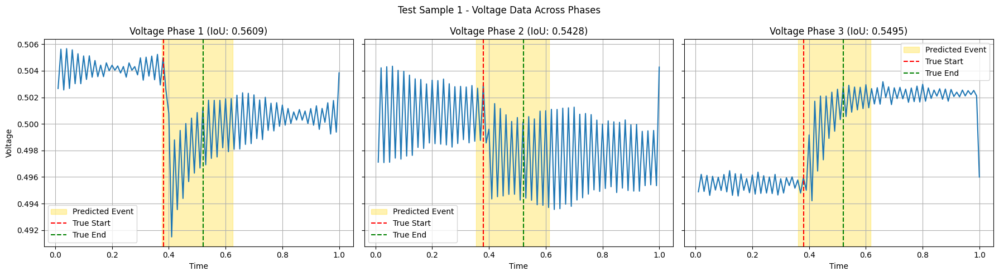

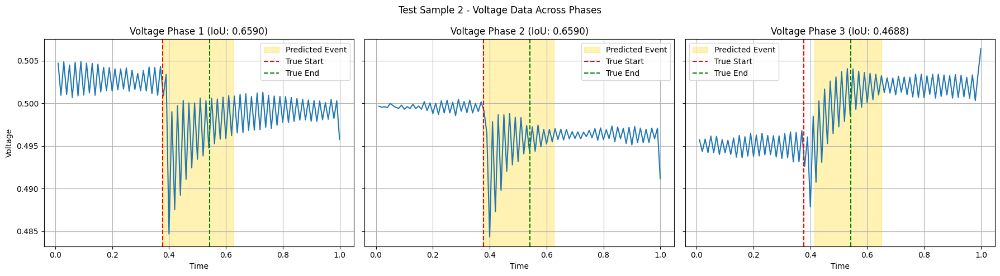

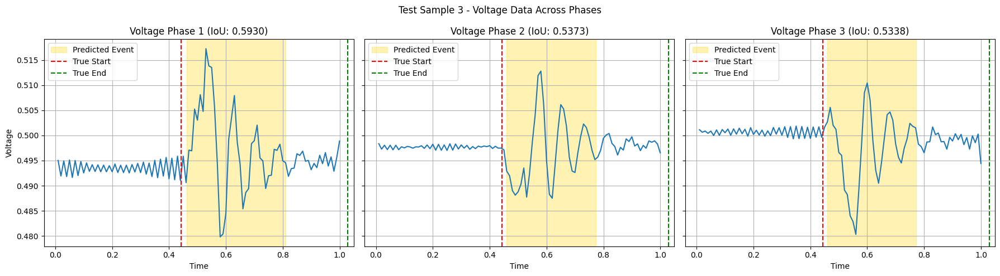

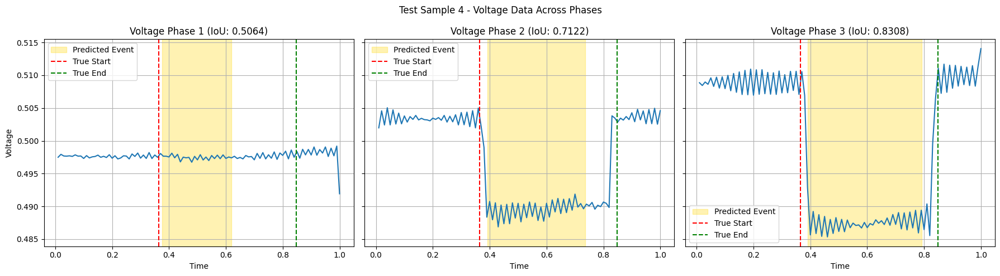

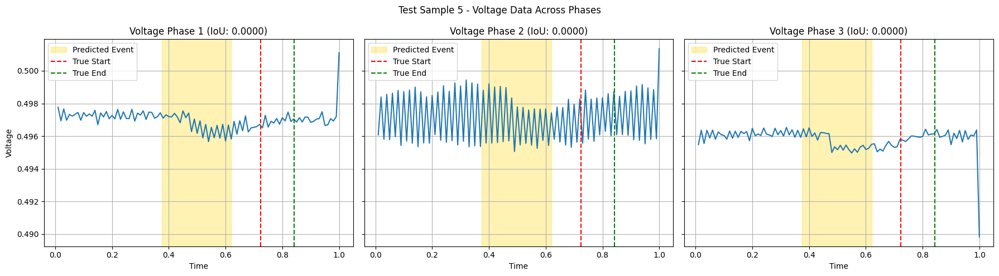

...

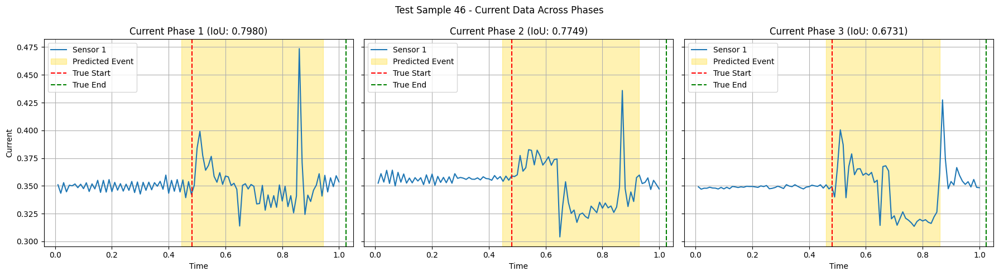

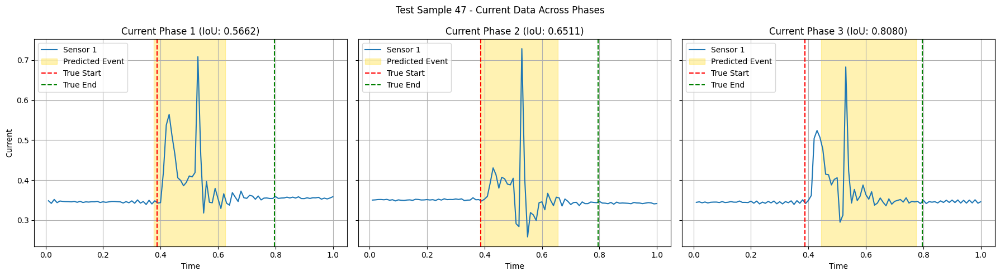

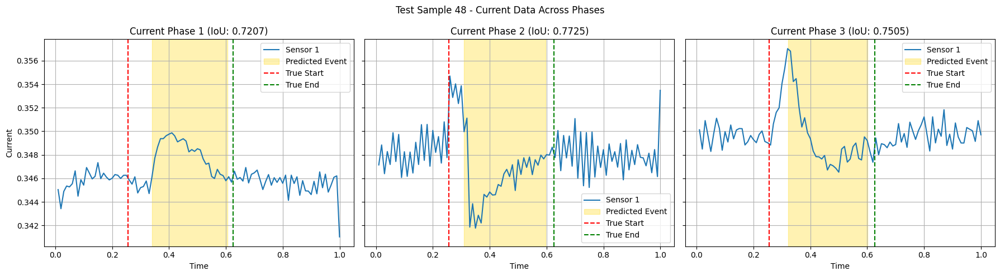

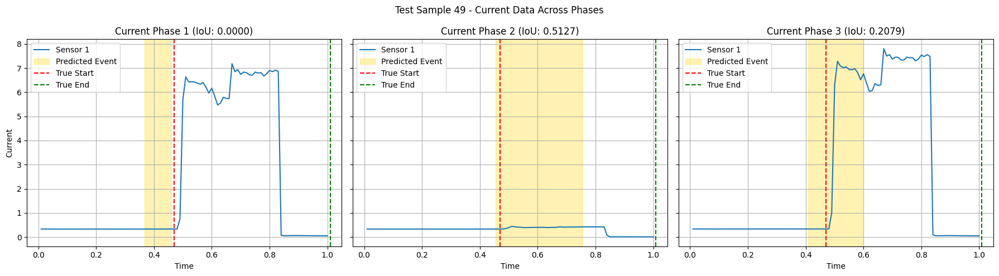

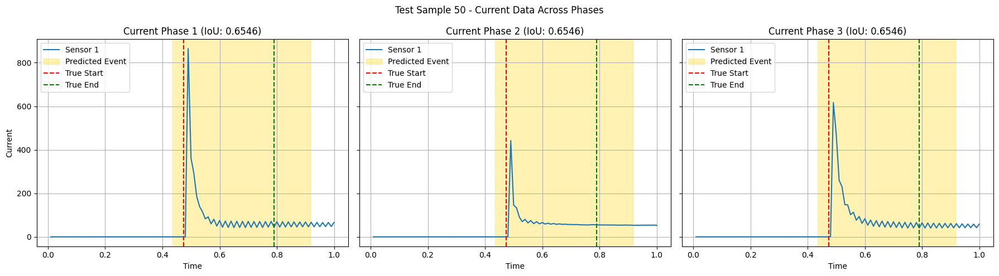

In [20]:
# Evaluation Function (Updated to return predictions and IoU scores)
def evaluate_model(model, X_test_data, y_test_data, batch_size=16, device="cuda"):
    model.eval()
    
    X_test_tensor = torch.tensor(X_test_data, dtype=torch.float32).to(device)
    y_test_tensor = torch.tensor(y_test_data, dtype=torch.float32).to(device)
    
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)
    
    test_loss = 0.0
    test_iou = 0.0
    all_predictions = []
    all_ious = []
    
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            y_pred = model(X_batch)
            loss = combined_loss(y_pred, y_batch)
            test_loss += loss.item()
            
            # Calculate IoU for each sample in batch
            pred_start, pred_end = y_pred[:, 0], y_pred[:, 1]
            true_start, true_end = y_batch[:, 0], y_batch[:, 1]
            
            # Calculate intersection and union for each sample
            intersection = torch.clamp(torch.min(pred_end, true_end) - torch.max(pred_start, true_start), min=0)
            union = (true_end - true_start) + (pred_end - pred_start) - intersection
            
            # Calculate IoU for each sample
            sample_ious = intersection / (union + 1e-6)
            all_ious.extend(sample_ious.cpu().numpy())
            
            # Store predictions
            all_predictions.append(y_pred.cpu())
    
    # Concatenate all predictions
    all_predictions = torch.cat(all_predictions, dim=0).numpy()
    
    test_loss /= len(test_loader)
    test_iou = sum(all_ious) / len(all_ious)
    
    return test_iou, all_predictions, np.array(all_ious)

# Visualization Function
def visualize_predictions(model, num_samples=50):
    # Ensure model is evaluated for each phase separately for both voltage and current
    y_pred_tensors = {}
    ious_scores = {}
    
    # Evaluate voltage phases
    print("\n=== Evaluating Voltage Phases ===")
    for phase in [1, 2, 3]:
        # Get test data for this phase
        X_test_seq = eval(f"X_test_v_phase{phase}_seq")
        y_test_seq = eval(f"y_test_phase{phase}_seq")
        
        print(f"Evaluating model on Voltage Phase {phase}...")
        mean_iou, y_pred_tensors[f'v_phase{phase}'], ious_scores[f'v_phase{phase}'] = evaluate_model(
            model, X_test_seq, y_test_seq, device=device
        )
        print(f"Mean IoU for Voltage Phase {phase}: {mean_iou:.4f}")
    
    # Evaluate current phases
    print("\n=== Evaluating Current Phases ===")
    for phase in [1, 2, 3]:
        # Get test data for this phase
        X_test_seq = eval(f"X_test_c_phase{phase}_seq")
        y_test_seq = eval(f"y_test_phase{phase}_seq")
        
        print(f"Evaluating model on Current Phase {phase}...")
        mean_iou, y_pred_tensors[f'c_phase{phase}'], ious_scores[f'c_phase{phase}'] = evaluate_model(
            model, X_test_seq, y_test_seq, device=device
        )
        print(f"Mean IoU for Current Phase {phase}: {mean_iou:.4f}")
    
    # Convert test labels to numpy
    y_test_tensors = {
        phase: eval(f"y_test_phase{phase}_seq")
        for phase in [1, 2, 3]
    }
    
    # Loop through each test sample and plot VOLTAGE phases
    for test_sample in range(min(num_samples, len(eval("X_test_v_phase1_seq")))):
        fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)  # 1 row, 3 columns
        
        for i, phase in enumerate([1, 2, 3]):
            # Fetch phase-specific data
            X_test_seq = eval(f"X_test_v_phase{phase}_seq")
            time_test_seq = eval(f"time_test_phase{phase}_seq") if 'time_test_phase1_seq' in globals() else None
            y_pred_tensor = y_pred_tensors[f'v_phase{phase}']
            y_test_tensor = y_test_tensors[phase]
            
            X_sample = X_test_seq[test_sample]  # Shape: (time_steps, features)
            
            # If time sequence is available, use it; otherwise create a synthetic time axis
            if time_test_seq is not None:
                time_sample = time_test_seq[test_sample]
            else:
                time_sample = np.arange(X_sample.shape[0])
            
            # Get predicted and true start/end times
            pred_start_time = y_pred_tensor[test_sample][0]
            pred_end_time = y_pred_tensor[test_sample][1]
            orig_start_time = y_test_tensor[test_sample][0]
            orig_end_time = y_test_tensor[test_sample][1]
            
            # Plot on the respective subplot
            ax = axes[i]
            num_sensors = X_sample.shape[1] - 1  # Number of features in input data
            
            for sensor_idx in range(min(3, num_sensors)):  # Plot at most 3 sensors for clarity
                ax.plot(time_sample, X_sample[:, sensor_idx])
            
            # Highlight predicted event window
            ax.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.3, label="Predicted Event")
            ax.axvline(orig_start_time, color='red', linestyle='dashed', label="True Start")
            ax.axvline(orig_end_time, color='green', linestyle='dashed', label="True End")
            
            # Calculate IoU for this sample
            sample_iou = ious_scores[f'v_phase{phase}'][test_sample]
            
            # Subplot-specific labels
            ax.set_xlabel('Time')
            if i == 0:
                ax.set_ylabel('Voltage')
            ax.set_title(f'Voltage Phase {phase} (IoU: {sample_iou:.4f})')
            ax.legend()
            ax.grid(True)
        
        # Main title for the entire figure
        plt.suptitle(f'Test Sample {test_sample+1} - Voltage Data Across Phases')
        plt.tight_layout()
        plt.savefig(f'sample_{test_sample+1}_voltage_prediction.png')  # Save figure
        plt.show()
    
    # Loop through each test sample and plot CURRENT phases
    for test_sample in range(min(num_samples, len(eval("X_test_c_phase1_seq")))):
        fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)  # 1 row, 3 columns
        
        for i, phase in enumerate([1, 2, 3]):
            # Fetch phase-specific data
            X_test_seq = eval(f"X_test_c_phase{phase}_seq")
            time_test_seq = eval(f"time_test_phase{phase}_seq") if 'time_test_phase1_seq' in globals() else None
            y_pred_tensor = y_pred_tensors[f'c_phase{phase}']
            y_test_tensor = y_test_tensors[phase]
            
            X_sample = X_test_seq[test_sample]  # Shape: (time_steps, features)
            
            # If time sequence is available, use it; otherwise create a synthetic time axis
            if time_test_seq is not None:
                time_sample = time_test_seq[test_sample]
            else:
                time_sample = np.arange(X_sample.shape[0])
            
            # Get predicted and true start/end times
            pred_start_time = y_pred_tensor[test_sample][0]
            pred_end_time = y_pred_tensor[test_sample][1]
            orig_start_time = y_test_tensor[test_sample][0]
            orig_end_time = y_test_tensor[test_sample][1]
            
            # Plot on the respective subplot
            ax = axes[i]
            num_sensors = X_sample.shape[1] - 1 # Number of features in input data
            
            for sensor_idx in range(min(3, num_sensors)):  # Plot at most 3 sensors for clarity
                ax.plot(time_sample, X_sample[:, sensor_idx], label=f'Sensor {sensor_idx+1}')
            
            # Highlight predicted event window
            ax.axvspan(pred_start_time, pred_end_time, color='gold', alpha=0.3, label="Predicted Event")
            ax.axvline(orig_start_time, color='red', linestyle='dashed', label="True Start")
            ax.axvline(orig_end_time, color='green', linestyle='dashed', label="True End")
            
            # Calculate IoU for this sample
            sample_iou = ious_scores[f'c_phase{phase}'][test_sample]
            
            # Subplot-specific labels
            ax.set_xlabel('Time')
            if i == 0:
                ax.set_ylabel('Current')
            ax.set_title(f'Current Phase {phase} (IoU: {sample_iou:.4f})')
            ax.legend()
            ax.grid(True)
        
        # Main title for the entire figure
        plt.suptitle(f'Test Sample {test_sample+1} - Current Data Across Phases')
        plt.tight_layout()
        plt.savefig(f'sample_{test_sample+1}_current_prediction.png')  # Save figure
        plt.show()

# Add this to the main execution section at the end
if __name__ == "__main__":
    # ... [existing code remains the same] ...
    
    # After final model evaluation, visualize predictions
    print("\n=== Visualizing Predictions on Test Data ===\n")
    visualize_predictions(model, num_samples=50)  # Adjust number of samples as needed

In [21]:
pip install torchinfo

Note: you may need to restart the kernel to use updated packages.


In [22]:
from torchinfo import summary

model = CNN_GRU_Attention(input_shape, hidden_dim=64, num_layers=3)
summary(model, input_size=(32, 100, input_shape))  #

NameError: name 'CNN_GRU_Attention' is not defined

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.ticker import MultipleLocator

# Create a sample time series
np.random.seed(42)
length = 100
time = np.arange(length)
# Create a simple signal with an event (e.g., anomaly or specific pattern)
signal = np.sin(time/10) + 0.3*np.random.randn(length)
# Add an anomaly in a specific region
anomaly_start, anomaly_end = 30, 60
signal[anomaly_start:anomaly_end] += 2

# Define ground truth and prediction boundaries
true_start, true_end = anomaly_start, anomaly_end
# Simulate a slightly off prediction
pred_start, pred_end = 35, 65

# Calculate IoU metrics
intersection = min(pred_end, true_end) - max(pred_start, true_start)
union = (true_end - true_start) + (pred_end - pred_start) - intersection
iou = intersection / union

# Create the figure
plt.figure(figsize=(10, 6))

# Plot the time series data
plt.plot(time, signal, 'k-', linewidth=1.5, label='Time Series Signal')

# Get y-axis limits for proper rectangle sizing
y_min, y_max = plt.ylim()
height = y_max - y_min

# Ground truth rectangle (green, transparent)
true_rect = patches.Rectangle((true_start, y_min), true_end-true_start, height,
                             linewidth=2, edgecolor='g', facecolor='g', alpha=0.2,
                             label='Ground Truth')
plt.gca().add_patch(true_rect)

# Prediction rectangle (blue, transparent)
pred_rect = patches.Rectangle((pred_start, y_min), pred_end-pred_start, height,
                             linewidth=2, edgecolor='b', facecolor='b', alpha=0.2,
                             label='Prediction')
plt.gca().add_patch(pred_rect)

# Intersection rectangle (darker color)
intersection_rect = patches.Rectangle((max(true_start, pred_start), y_min), 
                                     intersection, height,
                                     linewidth=0, facecolor='purple', alpha=0.4,
                                     label='Intersection')
plt.gca().add_patch(intersection_rect)

# Add a text box with IoU value
plt.text(68, y_min+3, f'IoU = {iou:.2f}', fontsize=14, 
         bbox=dict(facecolor='white', alpha=0.7, boxstyle='round,pad=0.5'))

# Mark the specific points of interest
plt.scatter([true_start, true_end], [signal[true_start], signal[true_end]], color='g', s=80, marker='o')
plt.scatter([pred_start, pred_end], [signal[pred_start], signal[pred_end]], color='b', s=80, marker='s')

# Add text annotations for the boundaries
plt.text(true_start-3, signal[true_start]+0.3, 'True Start', color='g', fontweight='bold')
plt.text(true_end-3, signal[true_end]+0.3, 'True End', color='g', fontweight='bold')
plt.text(pred_start-3, signal[pred_start]-0.5, 'Pred Start', color='b', fontweight='bold')
plt.text(pred_end-3, signal[pred_end]-0.5, 'Pred End', color='b', fontweight='bold')



# Add title and labels
plt.xlabel('Time(s)', fontsize=12)
plt.ylabel('Signal Value', fontsize=12)
plt.xlim(0, length)
plt.grid(True, linestyle='--', alpha=0.7)

# Move legend to upper left to avoid overlap with IoU score
plt.legend(loc='upper left')

# Add detailed formula description

plt.tight_layout()
plt.subplots_adjust(bottom=0.15)

# Uncomment the line below to save the figure
plt.savefig('iou_time_series_visualization.png', dpi=300, bbox_inches='tight')

plt.show()

In [ ]:
# import matplotlib.pyplot as plt
# import numpy as np

# def visualize_sample_45(model, device):
#     """
#     Function to visualize just sample 45 for both voltage and current phases
#     for inclusion in a thesis.
#     """
#     # Ensure model is evaluated for each phase separately for both voltage and current
#     y_pred_tensors = {}
#     ious_scores = {}
    
#     # Set the specific sample number
#     sample_num = 45
    
#     # Evaluate voltage phases
#     print("\n=== Evaluating Voltage Phases for Sample 45 ===")
#     for phase in [1, 2, 3]:
#         # Get test data for this phase
#         X_test_seq = eval(f"X_test_v_phase{phase}_seq")
#         y_test_seq = eval(f"y_test_phase{phase}_seq")
        
#         print(f"Evaluating model on Voltage Phase {phase}...")
#         mean_iou, y_pred_tensors[f'v_phase{phase}'], ious_scores[f'v_phase{phase}'] = evaluate_model(
#             model, X_test_seq, y_test_seq, device=device
#         )
#         print(f"Mean IoU for Voltage Phase {phase}: {mean_iou:.4f}")
    
#     # Evaluate current phases
#     print("\n=== Evaluating Current Phases for Sample 45 ===")
#     for phase in [1, 2, 3]:
#         # Get test data for this phase
#         X_test_seq = eval(f"X_test_c_phase{phase}_seq")
#         y_test_seq = eval(f"y_test_phase{phase}_seq")
        
#         print(f"Evaluating model on Current Phase {phase}...")
#         mean_iou, y_pred_tensors[f'c_phase{phase}'], ious_scores[f'c_phase{phase}'] = evaluate_model(
#             model, X_test_seq, y_test_seq, device=device
#         )
#         print(f"Mean IoU for Current Phase {phase}: {mean_iou:.4f}")
    
#     # Convert test labels to numpy
#     y_test_tensors = {
#         phase: eval(f"y_test_phase{phase}_seq")
#         for phase in [1, 2, 3]
#     }
    
#     # Visualize VOLTAGE for sample 45
#     fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)  # 1 row, 3 columns
    
#     for i, phase in enumerate([1, 2, 3]):
#         # Fetch phase-specific data
#         X_test_seq = eval(f"X_test_v_phase{phase}_seq")
#         time_test_seq = eval(f"time_test_phase{phase}_seq") if 'time_test_phase1_seq' in globals() else None
#         y_pred_tensor = y_pred_tensors[f'v_phase{phase}']
#         y_test_tensor = y_test_tensors[phase]
        
#         X_sample = X_test_seq[sample_num]  # Shape: (time_steps, features)
        
#         # If time sequence is available, use it; otherwise create a synthetic time axis
#         if time_test_seq is not None:
#             time_sample = time_test_seq[sample_num]
#         else:
#             time_sample = np.arange(X_sample.shape[0])
        
#         # Get predicted and true start/end times
#         pred_start_time = y_pred_tensor[sample_num][0]
#         pred_end_time = y_pred_tensor[sample_num][1]
#         orig_start_time = y_test_tensor[sample_num][0]
#         orig_end_time = y_test_tensor[sample_num][1]
        
#         # Plot on the respective subplot
#         ax = axes[i]
#         num_sensors = X_sample.shape[1] - 1  # Number of features in input data
        
#         for sensor_idx in range(min(3, num_sensors)):  # Plot at most 3 sensors for clarity
#             ax.plot(time_sample, X_sample[:, sensor_idx], label=f'Sensor {sensor_idx+1}')
        
#         # Highlight predicted event window
#         ax.axvspan(pred_start_time, pred_end_time, color='yellow', alpha=0.3, label="Predicted Event")
#         ax.axvline(orig_start_time, color='red', linestyle='dashed', label="True Start")
#         ax.axvline(orig_end_time, color='green', linestyle='dashed', label="True End")
        
#         # Calculate IoU for this sample
#         sample_iou = ious_scores[f'v_phase{phase}'][sample_num]
        
#         # Subplot-specific labels
#         ax.set_xlabel('Time')
#         if i == 0:
#             ax.set_ylabel('Sensor Value')
#         ax.set_title(f'Voltage Phase {phase} (IoU: {sample_iou:.4f})')
#         ax.legend()
#         ax.grid(True)
    
#     # Main title for the entire figure
#     plt.suptitle(f'Sample 45 - Voltage Data Across Phases')
#     plt.tight_layout()
#     plt.savefig('sample_45_voltage_prediction.png', dpi=300)  # Save figure with high resolution
#     plt.show()
    
#     # Visualize CURRENT for sample 45
#     fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)  # 1 row, 3 columns
    
#     for i, phase in enumerate([1, 2, 3]):
#         # Fetch phase-specific data
#         X_test_seq = eval(f"X_test_c_phase{phase}_seq")
#         time_test_seq = eval(f"time_test_phase{phase}_seq") if 'time_test_phase1_seq' in globals() else None
#         y_pred_tensor = y_pred_tensors[f'c_phase{phase}']
#         y_test_tensor = y_test_tensors[phase]
        
#         X_sample = X_test_seq[sample_num]  # Shape: (time_steps, features)
        
#         # If time sequence is available, use it; otherwise create a synthetic time axis
#         if time_test_seq is not None:
#             time_sample = time_test_seq[sample_num]
#         else:
#             time_sample = np.arange(X_sample.shape[0])
        
#         # Get predicted and true start/end times
#         pred_start_time = y_pred_tensor[sample_num][0]
#         pred_end_time = y_pred_tensor[sample_num][1]
#         orig_start_time = y_test_tensor[sample_num][0]
#         orig_end_time = y_test_tensor[sample_num][1]
        
#         # Plot on the respective subplot
#         ax = axes[i]
#         num_sensors = X_sample.shape[1] - 1  # Number of features in input data
        
#         for sensor_idx in range(min(3, num_sensors)):  # Plot at most 3 sensors for clarity
#             ax.plot(time_sample, X_sample[:, sensor_idx], label=f'Sensor {sensor_idx+1}')
        
#         # Highlight predicted event window
#         ax.axvspan(pred_start_time, pred_end_time, color='yellow', alpha=0.3, label="Predicted Event")
#         ax.axvline(orig_start_time, color='red', linestyle='dashed', label="True Start")
#         ax.axvline(orig_end_time, color='green', linestyle='dashed', label="True End")
        
#         # Calculate IoU for this sample
#         sample_iou = ious_scores[f'c_phase{phase}'][sample_num]
        
#         # Subplot-specific labels
#         ax.set_xlabel('Time')
#         if i == 0:
#             ax.set_ylabel('Sensor Value')
#         ax.set_title(f'Current Phase {phase} (IoU: {sample_iou:.4f})')
#         ax.legend()
#         ax.grid(True)
    
#     # Main title for the entire figure
#     plt.suptitle(f'Sample 45 - Current Data Across Phases')
#     plt.tight_layout()
#     plt.savefig('sample_45_current_prediction.png', dpi=300)  # Save figure with high resolution
#     plt.show()
    
#     print("Visualization of sample 45 complete. Images saved as 'sample_45_voltage_prediction.png' and 'sample_45_current_prediction.png'")

# # Usage example
# if __name__ == "__main__":
#     # Assuming 'model' and 'device' are already defined
#     visualize_sample_45(model, device)

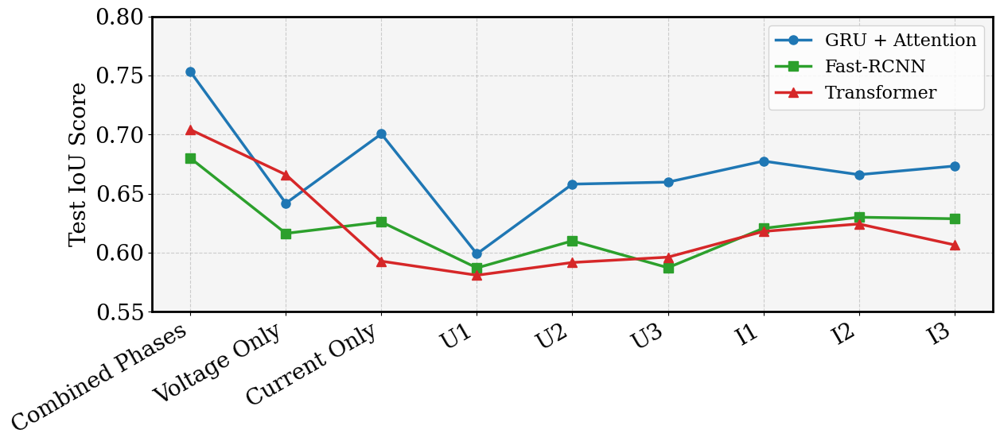

In [9]:
import matplotlib.pyplot as plt

# Set global plot style
plt.rcParams.update({
    'font.size': 20,
    'font.family': 'serif',
    'axes.titlesize': 20,
    'axes.labelsize': 20,
    'xtick.labelsize': 20,
    'ytick.labelsize': 20,
    'legend.fontsize': 16,
    'text.usetex': False
})

# Configuration categories
configs = [
    'Combined Phases', 'Voltage Only', 'Current Only',
    'U1', 'U2', 'U3',
    'I1', 'I2', 'I3'
]
x = list(range(len(configs)))

# Test IoU values for each model
gru_iou = [
    0.7532, 0.6418, 0.7005,
    0.5990, 0.6580, 0.6597,
    0.6775, 0.6660, 0.6733
]

transformer_iou = [
    0.7041, 0.6660, 0.5928,
    0.5809, 0.5917, 0.5962,
    0.6180, 0.6243, 0.6066
]

rcnn_iou = [
    0.6800, 0.6163, 0.6260,
    0.5871, 0.6100, 0.5873,
    0.6206, 0.6300, 0.6287
]

# Plotting
fig, ax = plt.subplots(figsize=(13, 6))

ax.plot(x, gru_iou, marker='o', label='GRU + Attention', linewidth=2.5, markersize=8, color='#1f77b4')
ax.plot(x, rcnn_iou, marker='s', label='Fast-RCNN', linewidth=2.5, markersize=8, color='#2ca02c')
ax.plot(x, transformer_iou, marker='^', label='Transformer', linewidth=2.5, markersize=8, color='#d62728')

# Format axis
ax.set_xticks(x)
ax.set_xticklabels(configs, rotation=30, ha='right')
ax.set_ylabel('Test IoU Score')
ax.set_ylim(0.55, 0.8)

# Styling
ax.grid(True, linestyle='--', alpha=0.6)
ax.set_facecolor('#f5f5f5')
for spine in ax.spines.values():
    spine.set_color('black')
    spine.set_linewidth(2)

# Legend and layout
ax.legend(frameon=True, loc='upper right')
plt.tight_layout()
plt.savefig('iou_lineplot_full_phases.png', dpi=300, bbox_inches='tight')
plt.show()
